In [5]:
import numpy as np
import matplotlib.pyplot as plt


In [6]:
X = np.array([
    [1.0, 1.0],
    [1.5, 2.0],
    [3.0, 4.0],
    [5.0, 7.0],
    [3.5, 5.0],
    [4.5, 5.0],
    [3.5, 4.5]
])

K = 2

print("Number of observations:", X.shape[0])
print("Number of variables:", X.shape[1])


Number of observations: 7
Number of variables: 2


In [7]:
# Compute Euclidean Distance

def compute_distance(point, centroid):
    distance = np.linalg.norm(point - centroid, ord=2)
    return distance


In [8]:
# K-Means++ Initialization

def initialize_centroids_plus_plus(X, K):
    # Select the first centroid randomly
    centroids = []

    first_index = np.random.choice(len(X))
    centroids.append(X[first_index])

    # Select remaining centroids
    for k in range(1, K):

        distances = []

        for point in X:

            # Distance from point to its nearest selected centroid
            min_distance = float("inf")

            for centroid in centroids:
                distance = compute_distance(point, centroid)

                if distance < min_distance:
                    min_distance = distance

            distances.append(min_distance ** 2)

        distances = np.array(distances)

        # Probability is proportional to squared distance
        probabilities = distances / np.sum(distances)

        # Select next centroid
        next_index = np.random.choice(
            len(X),
            p=probabilities
        )

        centroids.append(X[next_index])

    return np.array(centroids)



In [9]:
# Find Closest Centroid
def find_closest_centroid(point, centroids):
    
    distances = np.linalg.norm(
        centroids - point,
        axis=1
    )

    index = np.argmin(distances)

    return index


In [10]:
# Assign Clusters
def assign_clusters(X, centroids):
    
    idx = []

    for point in X:

        cluster = find_closest_centroid(
            point,
            centroids
        )

        idx.append(cluster)

    return np.array(idx)

In [11]:
# Compute New Centroids
def compute_centroids(X, idx, K):
    
    new_centroids = []

    for k in range(K):

        points = X[idx == k]

        # Mean of points in the cluster
        centroid = np.mean(points, axis=0)

        new_centroids.append(centroid)

    return np.array(new_centroids)

In [12]:
# Compute Cost
def compute_cost(X, idx, centroids):
    
    m = len(X)

    total = 0

    for i in range(m):

        centroid = centroids[idx[i]]

        total += np.sum(
            (X[i] - centroid) ** 2
        )

    return total / m


In [14]:
def run_kmeans(X, initial_centroids, max_iters=100):
    
    centroids = initial_centroids.copy()

    for i in range(max_iters):

        # Step 1: Assign observations to nearest centroid
        idx = assign_clusters(
            X,
            centroids
        )

        # Step 2: Compute new centroids
        new_centroids = compute_centroids(
            X,
            idx,
            len(centroids)
        )

        # Check convergence
        if np.allclose(
            new_centroids,
            centroids
        ):
            break

        centroids = new_centroids

    return centroids, idx, i + 1



In [15]:
np.random.seed(123)

initial_centroids = initialize_centroids_plus_plus(
    X,
    K
)

print("\nInitial Centroids selected using K-Means++:")
print(initial_centroids)


final_centroids, idx, iterations = run_kmeans(
    X,
    initial_centroids,
    max_iters=100
)

final_cost = compute_cost(
    X,
    idx,
    final_centroids
)


# ---------------------------------------------------------
# Display Results
# ---------------------------------------------------------

print("\nFinal Centroids:")
print(final_centroids)

print("\nCluster Assignment:")
print(idx)

print("\nFinal Cost:")
print(final_cost)

print("\nNumber of Iterations:")
print(iterations)


Initial Centroids selected using K-Means++:
[[3.5 4.5]
 [1.5 2. ]]

Final Centroids:
[[3.9  5.1 ]
 [1.25 1.5 ]]

Cluster Assignment:
[1 1 0 0 0 0 0]

Final Cost:
1.2178571428571427

Number of Iterations:
2


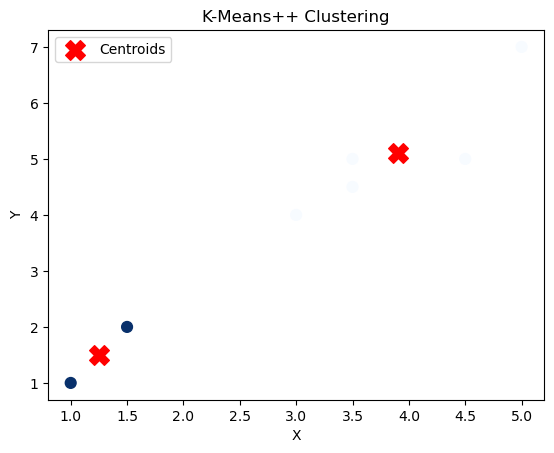

In [16]:
# Visualize Clusters


plt.scatter(
    X[:, 0],
    X[:, 1],
    c=idx,
    s=60,
    cmap="Blues"
)

plt.scatter(
    final_centroids[:, 0],
    final_centroids[:, 1],
    marker="X",
    color="red",
    s=200,
    label="Centroids"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("K-Means++ Clustering")
plt.legend()
plt.show()


Costs for different K values:
K = 2 Cost = 1.2178571428571427
K = 3 Cost = 0.35714285714285715
K = 4 Cost = 0.1845238095238095
K = 5 Cost = 0.10714285714285714


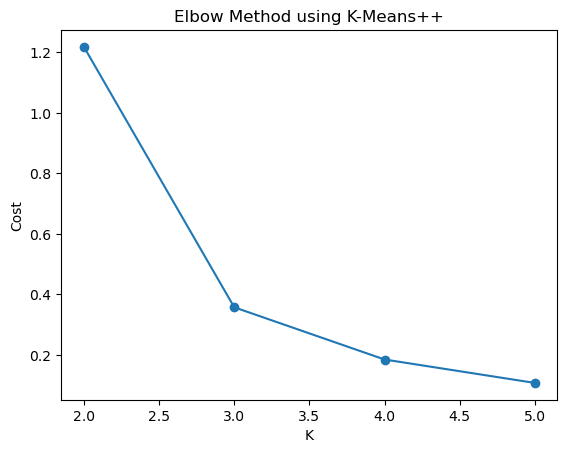

In [17]:
# Elbow Method using K-Means++

costs = []

for K_value in range(2, 6):

    np.random.seed(123)

    # K-Means++ initialization
    initial = initialize_centroids_plus_plus(
        X,
        K_value
    )

    # Run K-Means
    centroids, idx, iterations = run_kmeans(
        X,
        initial,
        max_iters=200
    )

    # Compute final cost
    cost = compute_cost(
        X,
        idx,
        centroids
    )

    costs.append(cost)


print("\nCosts for different K values:")

for k, cost in zip(range(2, 6), costs):
    print("K =", k, "Cost =", cost)


# Elbow plot

plt.plot(
    range(2, 6),
    costs,
    marker="o"
)

plt.xlabel("K")
plt.ylabel("Cost")
plt.title("Elbow Method using K-Means++")
plt.show()
